In [1]:

import pandas as pd
from pathlib import Path

# Locate the project folder
PROJECT_ROOT = Path.cwd()

# If the notebook is running from the notebooks folder,
# move one level up to the project root.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "model_inputs"

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTarget values in y_train:")
print(y_train.value_counts())


X_train: (5634, 20)
X_test: (1409, 20)
y_train: (5634,)
y_test: (1409,)

Target values in y_train:
Churn Label
0    4139
1    1495
Name: count, dtype: int64


In [2]:

# Check column names and data types
print("Training feature columns:")
print(X_train.columns.tolist())

print("\nData types:")
print(X_train.dtypes)

print("\nMissing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

print("\nTarget labels:")
print(y_train.unique())

print("\nDo training and testing columns match?")
print(X_train.columns.equals(X_test.columns))


Training feature columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'CLTV']

Data types:
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges            str
CLTV                   int64
dtype: object

Missing values in X_train: 0
Missing

In [3]:

import pandas as pd
import joblib

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Convert Total Charges to numeric where possible
for df in [X_train, X_test]:
    df["Total Charges"] = pd.to_numeric(
        df["Total Charges"], errors="coerce"
    )

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(
    include=["object", "str", "string", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)

# Preprocess numerical and categorical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Build both models
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train using training data only
logistic_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("\nBoth models trained successfully!")


Categorical features: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']
Numerical features: ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']

Both models trained successfully!


C:\Users\Dell\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [4]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

    print(f"\n--- {name} ---")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Stayed", "Churned"],
        zero_division=0
    ))

results_df = pd.DataFrame(results)
display(results_df.round(3))



--- Logistic Regression ---
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.65      0.58      0.61       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409


--- Decision Tree ---
              precision    recall  f1-score   support

      Stayed       0.82      0.80      0.81      1035
     Churned       0.49      0.51      0.50       374

    accuracy                           0.73      1409
   macro avg       0.65      0.66      0.66      1409
weighted avg       0.73      0.73      0.73      1409



,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.804,0.647,0.578,0.610
1,Decision Tree,0.727,0.486,0.513,0.499


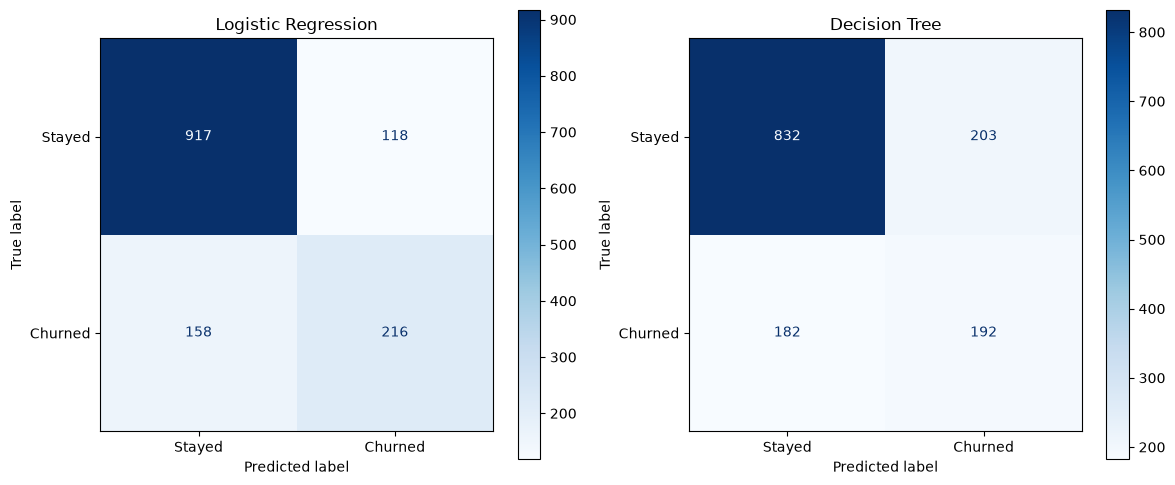

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(
    axes, predictions.items()
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Stayed", "Churned"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [6]:

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    logistic_model,
    models_dir / "logistic_regression_model.joblib"
)

joblib.dump(
    tree_model,
    models_dir / "decision_tree_model.joblib"
)

results_df.to_csv(
    PROJECT_ROOT / "model_evaluation_results.csv",
    index=False
)

print("Models and evaluation results saved successfully!")


Models and evaluation results saved successfully!


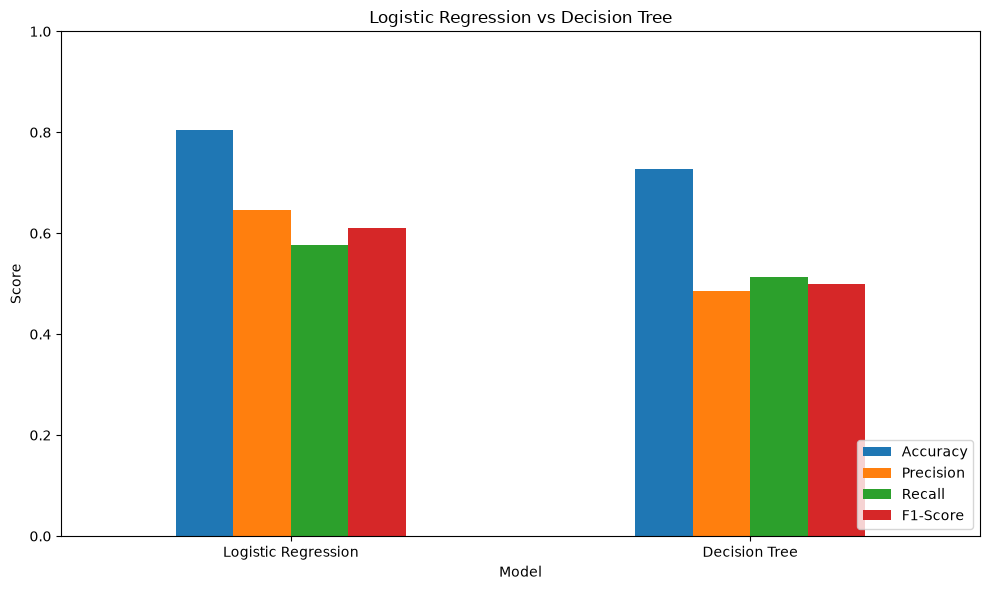

In [7]:

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 6), ylim=(0, 1), rot=0)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [8]:
print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.8041     0.6467  0.5775    0.6102
      Decision Tree    0.7268     0.4861  0.5134    0.4993


## Final Observations — Model Evaluation

1. **Accuracy:** Logistic Regression achieved 80.41% accuracy, while Decision Tree achieved 72.68%.

2. **Precision:** Logistic Regression achieved 64.67% precision, compared with 48.61% for Decision Tree.

3. **Recall:** Logistic Regression achieved 57.75% recall, while Decision Tree achieved 51.34%.

4. **F1-score:** Logistic Regression achieved an F1-score of 61.02%, compared with 49.93% for Decision Tree.

5. **Model comparison:** Logistic Regression performed better than Decision Tree across all four evaluation metrics on the test dataset.

6. **Business interpretation:** Logistic Regression is the stronger candidate among the two models tested. However, its recall of 57.75% indicates that it still misses some customers who actually churn.

**Conclusion:** Logistic Regression is selected as the preferred model based on the current evaluation results. Further improvements could focus on increasing churn recall while maintaining a reasonable precision score.